In [18]:
from pathlib import Path
import pandas as pd
from rdkit import Chem
from rdkit.Chem import PandasTools
from rdkit.Geometry import Point3D
from mordred import Calculator, descriptors
from joblib import Parallel, delayed
import numpy as np
from sklearn.model_selection import cross_validate, KFold
from skfp.model_selection import randomized_scaffold_train_test_split
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import re
from xgboost import XGBRegressor

In [17]:
import sys

#仓库根：从当前目录往上找带 config.py 的目录（git clone 和直接下载 zip 都能用）
ROOT = Path.cwd()
while not (ROOT / "config.py").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
import config

In [19]:
SEED = 114514
HARTREE = 2625.5
BEGIN = 0
END = 713

In [20]:
def xyz_to_mol(smiles, path):
    mol = Chem.AddHs(Chem.MolFromSmiles(smiles))    # 拓扑 + 氢（顺序：重原子，然后氢）
    lines = open(path).read().splitlines()          # 读整个文件
    n = int(lines[0])                               # 第1行 = 原子数
    xyz = np.array([l.split()[1:] for l in lines[2:2+n]], float)  # 取后3列 = 坐标
    conf = Chem.Conformer(n)                        # 建一个空构象
    for i, p in enumerate(xyz):
        conf.SetAtomPosition(i, Point3D(*p))        # 第 i 个原子 ← 第 i 行坐标
    mol.AddConformer(conf, assignId = True)         # 装进分子
    return mol

def mol_to_feat(mol):
    names = [
        'BCUTd-1l', 'BCUTv-1l', 'ETA_dEpsilon_B', 'GATS3s', 'AETA_beta',
        'ATSC1v', 'RPCG', 'AATS4i', 'AXp-5d', 'AATSC0p', 'AMID_O',
        'ETA_shape_y', 'MDEC-33', 'AATSC2i', 'SLogP', 'ETA_epsilon_5',
        'AATSC0i', 'GATS1v', 'AATS4se', 'JGI4', 'GATS2i', 'AXp-7dv', 'GATS2s',
        'AETA_beta_s', 'ATSC8se', 'VSA_EState4', 'GATS4s', 'AATS1i', 'ATSC1Z',
        'ATSC2i', 'AATS6i', 'ATSC2d', 'MATS1Z', 'PEOE_VSA12', 'NdsN', 'GATS1se',
        'MDEN-23', 'SlogP_VSA2', 'ATSC2dv', 'IC0', 'ATSC1i', 'ATSC4dv',
        'GATS3c', 'AXp-1dv', 'MIC1'
    ]
    res = calc(mol)
    return [res[name] for name in names]

def read_energy(path):
    text = path.read_text(encoding = "utf-8")
    return float(re.search(r'"total energy"\s*:\s*(-?[\d.eE+-]+)', text).group(1))

def bde_of_bond(folder):
    Ep = read_energy(folder / "parent.json")

    E_v = {}
    for name in ("fragA", "fragB"):                 # 垂直：片段保持父几何
        E_v[name] = read_energy(folder / f"{name}_u1.json")
    v = (E_v["fragA"] + E_v["fragB"] - Ep) * HARTREE
    return v

In [21]:
# 处理 .xlsx 数据，生成 mol 类
file = config.DATA_TDT / "fixed.xlsx"
df = pd.read_excel(file)[BEGIN : END].reset_index(drop = True)
PandasTools.RenderImagesInAllDataFrames()
PandasTools.AddMoleculeColumnToFrame(df, "SMILES", "ROMol", False)
mols = df["ROMol"].tolist()
calc = Calculator(descriptors, ignore_3D = True)

In [22]:
TAR = config.PARENTS

PATS = Chem.MolFromSmarts("[#6]-[N+](=O)[O-]")

trigger_wbo = []
max_wbo = []

for cur, i in enumerate(sorted(TAR.glob("parent_*"))[BEGIN : END]):
    mol = Chem.AddHs(df["ROMol"][cur])
    wbo = pd.read_csv(i / "wbo", sep = r"\s+", names=["a", "b", "wbo"])
    wbo_d = {(min(a, b) - 1, max(a, b) - 1) : w for a, b, w in wbo.values}

    all_bond = []
    for b in mol.GetBonds():
        if b.GetBeginAtom().GetAtomicNum() < 2 or b.GetEndAtom().GetAtomicNum() < 2:
            continue
        min_index = min(b.GetBeginAtomIdx(), b.GetEndAtomIdx())
        max_index = max(b.GetBeginAtomIdx(), b.GetEndAtomIdx())
        w = wbo_d.get((min_index, max_index))
        if w is not None:
            all_bond.append(w)
    max_wbo.append(max(all_bond))

len(max_wbo)

713

In [23]:
WORK = config.XTB_WORK / "BDE"

BDE_v = []
NAMES = ["C-NO2", "N-NO2", "O-NO2"]

for i in df.index:
    sub = WORK / f"BDE_{i + BEGIN:04d}"

    vals = []
    for name in NAMES:
        v = bde_of_bond(sub / f"{name}") if (sub / f"{name}").exists() else None
        if v is not None:
            vals.append(v)
        else:
            vals.append(np.nan)
    
    BDE_v.append(vals)

len(BDE_v)

713

In [7]:
feats = Parallel(n_jobs = -1)(delayed(mol_to_feat)(mol) for mol in mols)

In [8]:
x_all = np.concatenate([np.array(feats), np.array(max_wbo).reshape(-1, 1), np.array(BDE_v)], axis = 1)
y_all = np.array(df["Td(°C)"], dtype = np.float64)

clf = XGBRegressor(
    n_estimators = 800,
    learning_rate = 0.05,
    max_depth = 6,
    reg_lambda = 1.0,
    n_jobs = -1,
    random_state = SEED
)
scores = cross_validate(
    clf, x_all, y_all,
    cv = KFold(n_splits = 10, shuffle = True, random_state = SEED),
    scoring = ["neg_mean_squared_error", "neg_mean_absolute_error", "r2"],
    n_jobs = -1
)
rmse = ((-scores["test_neg_mean_squared_error"]) ** 0.5).mean()
mae = np.abs(scores["test_neg_mean_absolute_error"]).mean()
r2 = scores["test_r2"]
print(rmse, mae, r2.mean(), r2.std(), r2, sep = '\n')

40.44771935379951
30.355706428115916
0.6296873056009129
0.04449002648321485
[0.65840685 0.67174189 0.62177773 0.54472483 0.60005523 0.69033153
 0.58587411 0.65843474 0.66880699 0.59671916]


In [11]:
x_train, x_test, y_train, y_test = randomized_scaffold_train_test_split(
    df["SMILES"], df["Td(°C)"],
    train_size = 0.8, test_size = 0.2,
    random_state = 323922
)

x_train_mol, idx_train = [], []
for i in x_train:
    for j in range(len(df)):
        if i == df.loc[j, "SMILES"]:
            x_train_mol.append(df.loc[j, "ROMol"])
            idx_train.append(j)
            break

x_test_mol, idx_test = [], []
for i in x_test:
    for j in range(len(df)):
        if i == df.loc[j, "SMILES"]:
            x_test_mol.append(df.loc[j, "ROMol"])
            idx_test.append(j)
            break

x_train = Parallel(n_jobs = -1)(delayed(mol_to_feat)(mol) for mol in x_train_mol)
for i, idx in enumerate(idx_train):
    x_train[i].append(max_wbo[idx])
    x_train[i] += BDE_v[idx]

x_test = Parallel(n_jobs = -1)(delayed(mol_to_feat)(mol) for mol in x_test_mol)
for i, idx in enumerate(idx_test):
    x_test[i].append(max_wbo[idx])
    x_test[i] += BDE_v[idx]

0.5541255526869125 29.026989349789094 37.133321961645386


,x_test,y_test,predict,bias
613,,321.0,245.402832,75.597168
161,,351.0,256.519073,94.480927
198,,225.6,153.224319,72.375681
271,,116.0,199.085693,83.085693
411,,56.0,152.153854,96.153854
501,,50.0,130.031937,80.031937
522,,241.0,155.451019,85.548981
402,,220.0,290.752808,70.752808
83,,135.0,249.120148,114.120148
46,,80.0,177.039886,97.039886

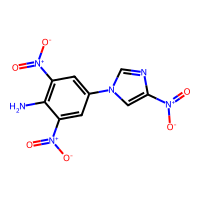
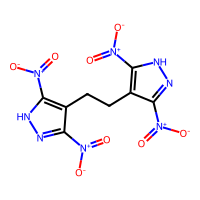
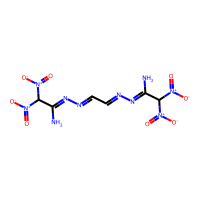
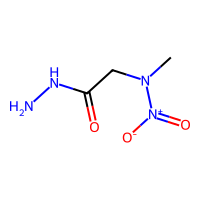
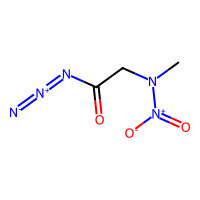
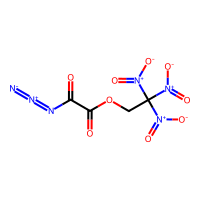
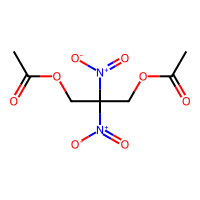
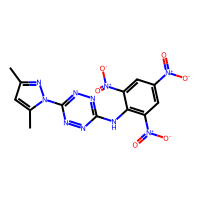
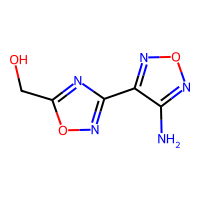
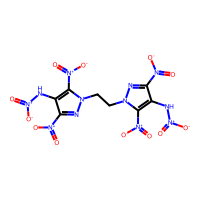

In [12]:
clf = XGBRegressor(
    n_estimators = 800,
    learning_rate = 0.05,
    max_depth = 6,
    reg_lambda = 1.0,
    n_jobs = -1,
    random_state = SEED
)

clf.fit(x_train, y_train)
y_pre = clf.predict(x_test)

PandasTools.RenderImagesInAllDataFrames(images = True)
df1 = pd.DataFrame({
    "x_test": x_test_mol,
    "y_test": y_test
})
df1["predict"] = y_pre
print(r2_score(y_test, y_pre), mean_absolute_error(y_test, y_pre), mean_squared_error(y_test, y_pre) ** 0.5)
df1["bias"] = abs(y_pre - y_test)
df1[df1.bias > 70]